CV LAB 4 & 5

---


NAME: ZAINA FATHIMA

---


USN: 1RUA24CSE0553

In [ ]:
!pip install opencv-python numpy matplotlib scikit-image

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

print("Libraries imported successfully!")

Libraries imported successfully!


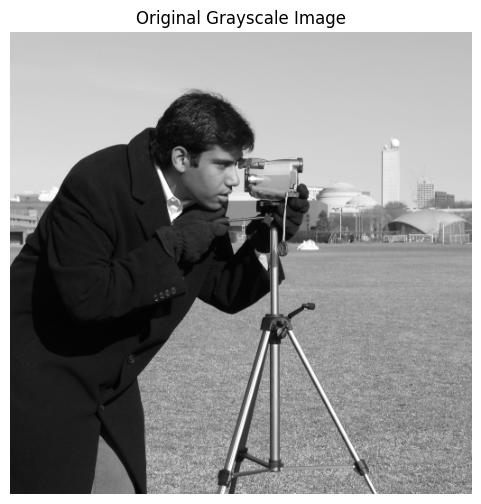

Image loaded successfully!
Image shape: (512, 512)


In [ ]:
# Load grayscale image
image = data.camera().astype(np.uint8)

# Display original image
plt.figure(figsize=(6, 6))
plt.imshow(image, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

print("Image loaded successfully!")
print("Image shape:", image.shape)

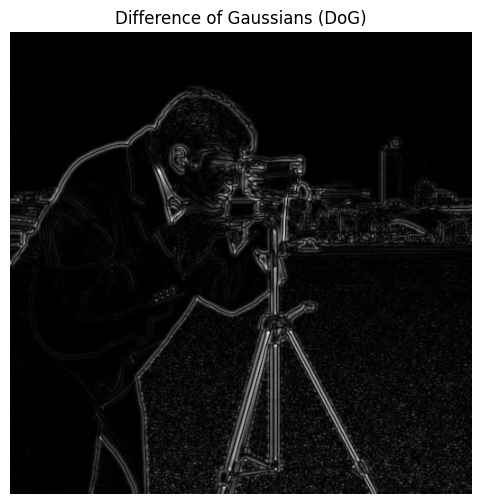

In [ ]:
# DoG Implementation

sigma1 = 1.0
sigma2 = 2.0

# Apply Gaussian blur at two different scales
g1 = cv2.GaussianBlur(image, (0, 0), sigma1)
g2 = cv2.GaussianBlur(image, (0, 0), sigma2)

# Calculate Difference of Gaussians
dog = cv2.absdiff(g1, g2)

# Normalize the result
dog_display = cv2.normalize(
    dog, None, 0, 255, cv2.NORM_MINMAX
)

# Display result
plt.figure(figsize=(6, 6))
plt.imshow(dog_display, cmap='gray')
plt.title("Difference of Gaussians (DoG)")
plt.axis("off")
plt.show()

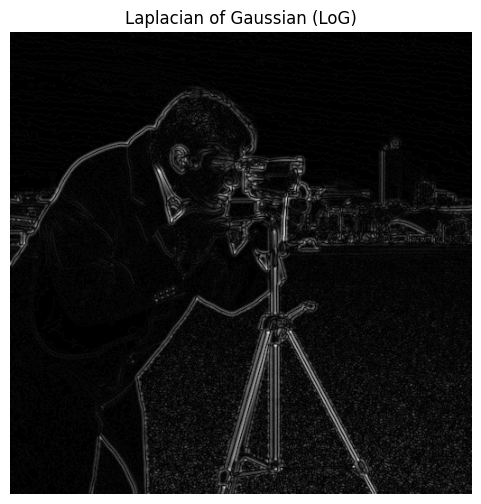

In [ ]:
# LoG Implementation

sigma = 1.2

# Apply Gaussian smoothing
blur = cv2.GaussianBlur(image, (0, 0), sigma)

# Apply Laplacian operator
laplacian = cv2.Laplacian(blur, cv2.CV_64F)

# Normalize the result
log_display = cv2.normalize(
    np.abs(laplacian),
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Display result
plt.figure(figsize=(6, 6))
plt.imshow(log_display, cmap='gray')
plt.title("Laplacian of Gaussian (LoG)")
plt.axis("off")
plt.show()

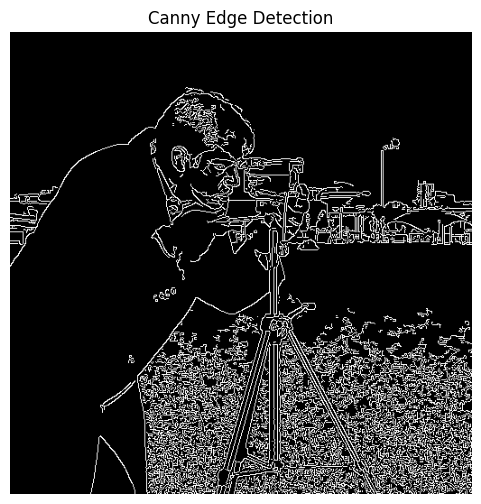

In [ ]:
# Canny Edge Detection

low_threshold = 50
high_threshold = 150

canny = cv2.Canny(
    image,
    low_threshold,
    high_threshold
)

# Display result
plt.figure(figsize=(6, 6))
plt.imshow(canny, cmap='gray')
plt.title("Canny Edge Detection")
plt.axis("off")
plt.show()

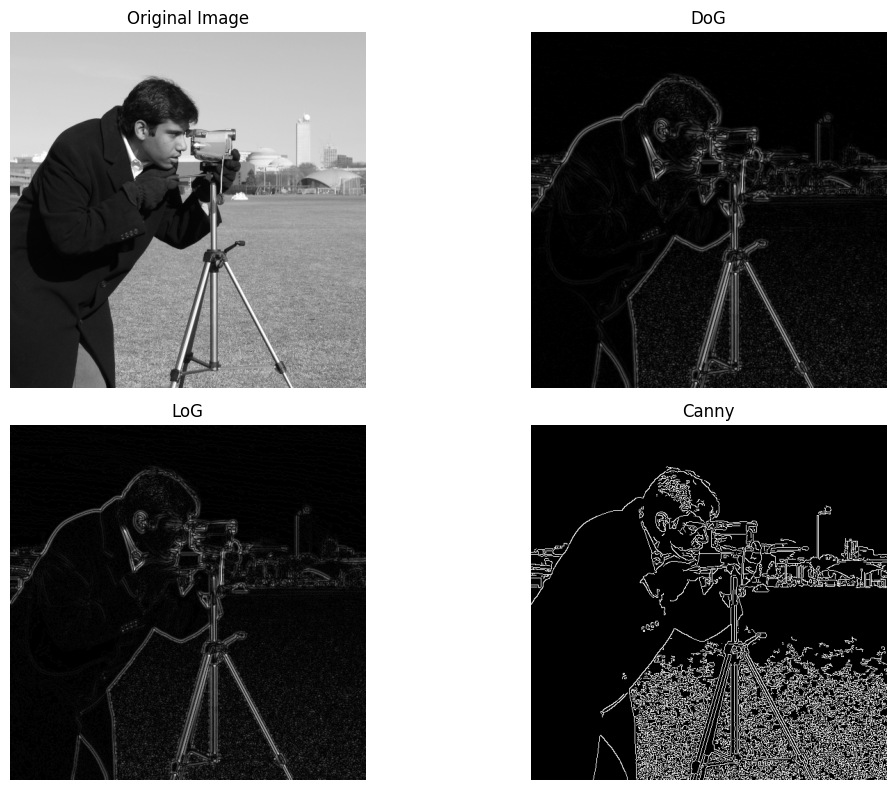

In [ ]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(dog_display, cmap="gray")
plt.title("DoG")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(log_display, cmap="gray")
plt.title("LoG")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(canny, cmap="gray")
plt.title("Canny")
plt.axis("off")

plt.tight_layout()
plt.show()

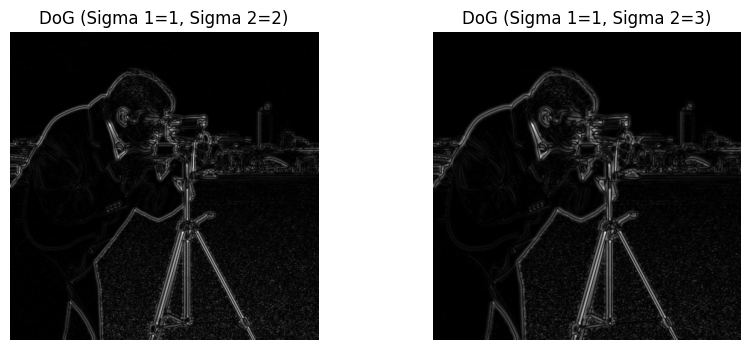

In [ ]:
sigma1 = 1.0
sigma2 = 3.0

g1 = cv2.GaussianBlur(image, (0, 0), sigma1)
g2 = cv2.GaussianBlur(image, (0, 0), sigma2)

dog_new = cv2.absdiff(g1, g2)

dog_new = cv2.normalize(
    dog_new, None, 0, 255, cv2.NORM_MINMAX
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(dog_display, cmap='gray')
plt.title("DoG (Sigma 1=1, Sigma 2=2)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(dog_new, cmap='gray')
plt.title("DoG (Sigma 1=1, Sigma 2=3)")
plt.axis("off")

plt.show()

Observation :

Increasing Sigma 2 from 2.0 to 3.0 increases the difference between the smoothing scales. This highlights broader structures and changes the edge response.

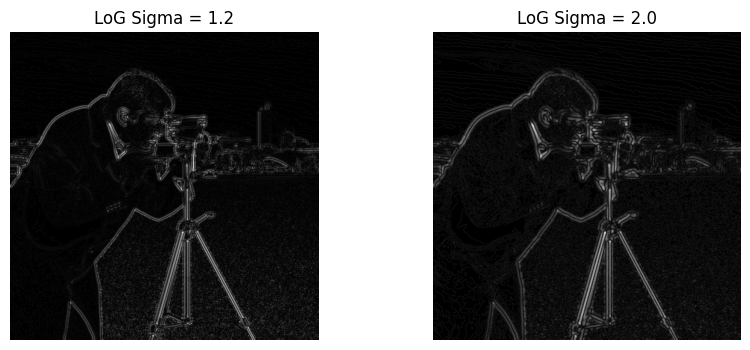

In [ ]:
sigma = 2.0

blur_new = cv2.GaussianBlur(image, (0, 0), sigma)

laplacian_new = cv2.Laplacian(
    blur_new, cv2.CV_64F
)

log_new = cv2.normalize(
    np.abs(laplacian_new),
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(log_display, cmap='gray')
plt.title("LoG Sigma = 1.2")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(log_new, cmap='gray')
plt.title("LoG Sigma = 2.0")
plt.axis("off")

plt.show()

Observation :

Increasing Sigma to 2.0 produces more smoothing before applying the Laplacian. Fine details and small edges are suppressed, while larger structures remain visible.

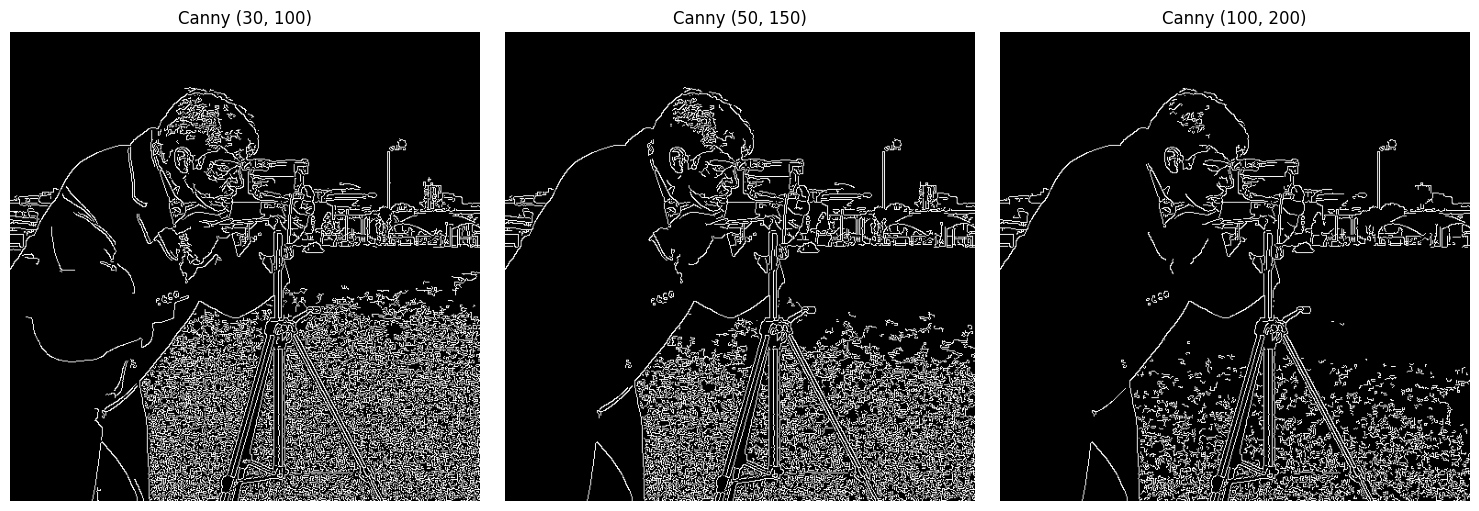

In [ ]:
thresholds = [
    (30, 100),
    (50, 150),
    (100, 200)
]

plt.figure(figsize=(15, 5))

for i, (low, high) in enumerate(thresholds):

    edges = cv2.Canny(image, low, high)

    plt.subplot(1, 3, i+1)
    plt.imshow(edges, cmap='gray')
    plt.title(f"Canny ({low}, {high})")
    plt.axis("off")

plt.tight_layout()
plt.show()

Observation :

(30,100): Detects more edges, including weaker edges and some unwanted details.
(50,150): Provides a balanced edge detection result.
(100,200): Detects stronger edges but may miss weaker edges.

| Method | Edge thickness   | Noise sensitivity | Continuity | Remarks                                   |
| ------ | ---------------- | ----------------- | ---------- | ----------------------------------------- |
| DoG    | Relatively thick | Moderate          | Moderate   | Highlights structures at different scales |
| LoG    | Relatively thick | High              | Moderate   | Detects second-derivative changes         |
| Canny  | Thin             | Low               | High       | Produces clear and connected edges        |


Three observations comparing DoG, LoG and Canny

---


DoG highlights image structures by subtracting two Gaussian-smoothed images.
LoG detects edges using second-order derivatives and is affected by noise.
Canny produces thin and well-connected edges using multiple processing stages.

Why is Gaussian smoothing useful before derivative-based edge detection?

Gaussian smoothing reduces unwanted noise and small intensity variations. This prevents derivative operators from detecting false edges and improves edge detection accuracy.

EXPERIMENT 5: Feature Extraction using SIFT

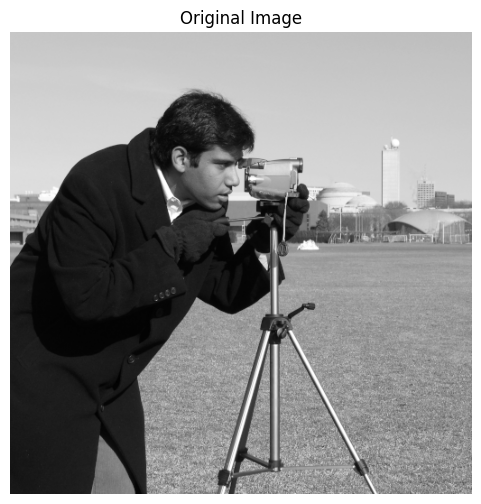

Image loaded successfully!


In [ ]:
import cv2
import matplotlib.pyplot as plt
from skimage import data

# Load grayscale image
image = data.camera().astype("uint8")

# Display original image
plt.figure(figsize=(6, 6))
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")
plt.show()

print("Image loaded successfully!")

In [ ]:
# Create SIFT detector
sift = cv2.SIFT_create()

print("SIFT detector created successfully!")

SIFT detector created successfully!


In [ ]:
# Detect keypoints and compute descriptors
keypoints, descriptors = sift.detectAndCompute(
    image, None
)

# Print information
print("Number of keypoints:", len(keypoints))

if descriptors is not None:
    print("Descriptor shape:", descriptors.shape)
    print("Descriptor length:", descriptors.shape[1])

Number of keypoints: 791
Descriptor shape: (791, 128)
Descriptor length: 128


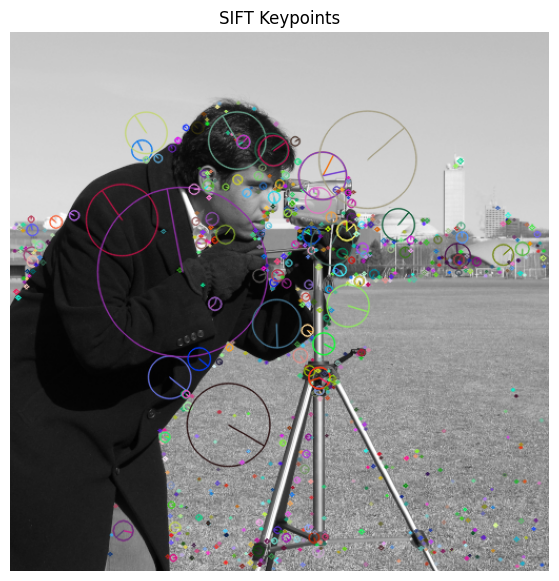

In [ ]:
# Draw keypoints
output = cv2.drawKeypoints(
    image,
    keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Display output
plt.figure(figsize=(10, 7))
plt.imshow(output, cmap="gray")
plt.title("SIFT Keypoints")
plt.axis("off")
plt.show()

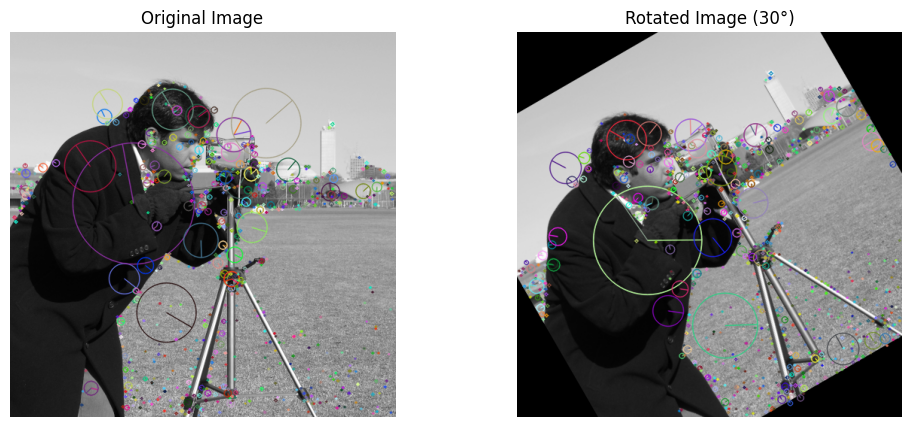

Original keypoints: 791
Rotated keypoints: 896


In [ ]:
# Rotate image by 30 degrees

h, w = image.shape

center = (w // 2, h // 2)

M = cv2.getRotationMatrix2D(center, 30, 1.0)

rotated_image = cv2.warpAffine(
    image, M, (w, h)
)

# Detect SIFT keypoints in rotated image
rotated_keypoints, rotated_descriptors = sift.detectAndCompute(
    rotated_image, None
)

# Draw keypoints
rotated_output = cv2.drawKeypoints(
    rotated_image,
    rotated_keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Display
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(output, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated_output, cmap='gray')
plt.title("Rotated Image (30°)")
plt.axis("off")

plt.show()

print("Original keypoints:", len(keypoints))
print("Rotated keypoints:", len(rotated_keypoints))

Observation:

After rotating the image by 30°, SIFT is still able to detect distinctive features. This demonstrates its rotation-invariant property.

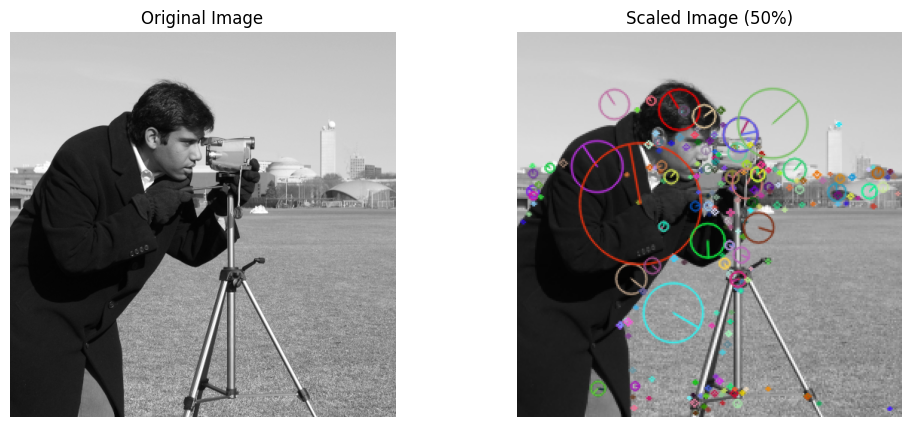

Original keypoints: 791
Scaled keypoints: 241


In [ ]:
# Resize image to 50%
scaled_image = cv2.resize(
    image,
    None,
    fx=0.5,
    fy=0.5
)

# Detect keypoints
scaled_keypoints, scaled_descriptors = sift.detectAndCompute(
    scaled_image, None
)

# Draw keypoints
scaled_output = cv2.drawKeypoints(
    scaled_image,
    scaled_keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Display
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(scaled_output, cmap='gray')
plt.title("Scaled Image (50%)")
plt.axis("off")

plt.show()

print("Original keypoints:", len(keypoints))
print("Scaled keypoints:", len(scaled_keypoints))

Observation:

SIFT can detect distinctive features even when the image size changes. This demonstrates scale invariance.

In [ ]:
# Verify descriptor dimensions

print("Number of keypoints:", len(keypoints))

print("Descriptor matrix shape:", descriptors.shape)

print("Descriptor dimensions:", descriptors.shape[1])

if descriptors.shape[1] == 128:
    print("Verification Successful: Each descriptor has 128 values.")
else:
    print("Verification Failed")

Number of keypoints: 791
Descriptor matrix shape: (791, 128)
Descriptor dimensions: 128
Verification Successful: Each descriptor has 128 values.


Keypoints in image 1: 791
Keypoints in image 2: 866
Good matches: 476


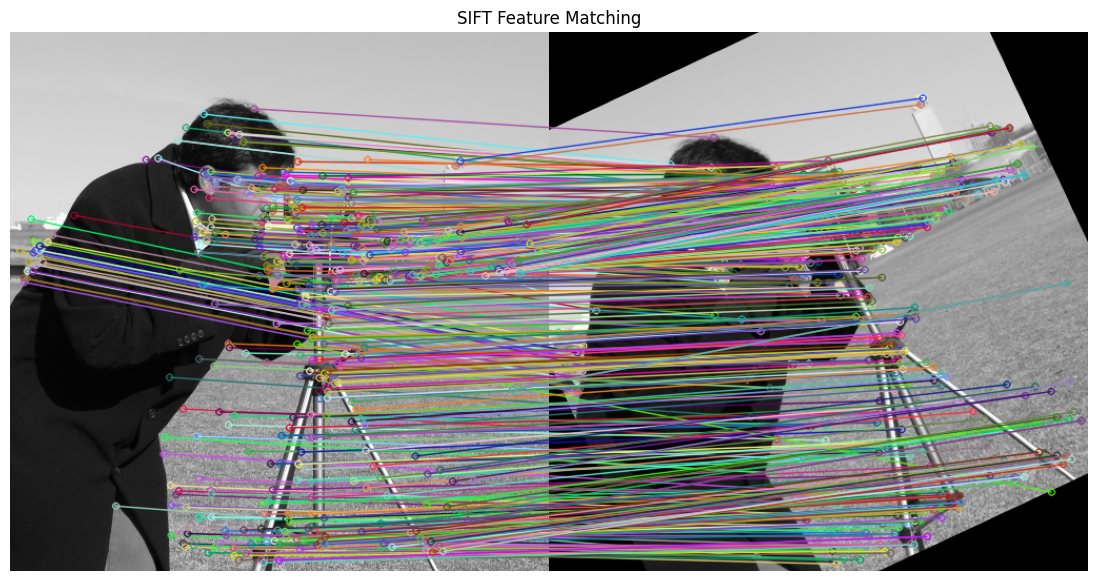

In [ ]:
# Create two related images

img1 = data.camera().astype("uint8")

h, w = img1.shape
center = (w // 2, h // 2)

M = cv2.getRotationMatrix2D(center, 25, 1.0)

img2 = cv2.warpAffine(img1, M, (w, h))

# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and descriptors
kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

# Brute Force matcher
bf = cv2.BFMatcher(cv2.NORM_L2)

# Match descriptors
matches = bf.knnMatch(des1, des2, k=2)

# Lowe's ratio test
good_matches = []

for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

# Draw matching features
result = cv2.drawMatches(
    img1,
    kp1,
    img2,
    kp2,
    good_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Print information
print("Keypoints in image 1:", len(kp1))
print("Keypoints in image 2:", len(kp2))
print("Good matches:", len(good_matches))

# Display
plt.figure(figsize=(14, 7))
plt.imshow(result, cmap="gray")
plt.title("SIFT Feature Matching")
plt.axis("off")
plt.show()

  Observations:

---


SIFT successfully detects distinctive keypoints in the grayscale image.
Each SIFT descriptor contains 128 numerical values.
SIFT detects features even after rotating the image by 30°.
SIFT can identify distinctive features when the image is resized.
Feature matching connects corresponding keypoints between two related images.

Why is SIFT more useful for feature matching than comparing raw pixel values?

SIFT extracts distinctive features and descriptors that are relatively robust to rotation, scale and illumination changes. Raw pixel comparison is more sensitive to these changes. Therefore, SIFT is more reliable for matching features between images.